# Goal Curriculum Learning with SAC + HER on panda-gym

this notebook is a preliminary test to see whether the order we learn the goals really matter to improve the learning efficency.

Three strategies: 
1. **`Hard to easy`** 
2. **`random`** : the order of goals is completely random
3. **`Easy to hard`** 

Here we only use one simple environement :`PandaPush-v3`






In [1]:
import time
import copy
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gymnasium as gym
import panda_gym 

from stable_baselines3 import SAC
from stable_baselines3.her import HerReplayBuffer
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.utils import set_random_seed

_trapz = getattr(np, "trapezoid", None) or np.trapz

print("gymnasium:", gym.__version__)


gymnasium: 1.3.0


In [2]:
ENV_ID = "PandaPush-v3"

STRATEGIES = ["hardtoeasy", "random", "easytohard"]


TOTAL_TIMESTEPS = 100_000

# test on diff seeds 
SEEDS = [10,11,12]

EVAL_FREQ = 2_000          # frequence of evaluation
N_EVAL_EPISODES = 50       # number of episodes to evaluate the model 

# Hyperparametres SAC + HER 
SAC_KWARGS = dict(
    learning_rate=1e-3,
    buffer_size=200_000,
    learning_starts=1_000,
    batch_size=256,
    train_freq=1,
    gradient_steps=1,
    gamma=0.95,
    tau=0.05,
    policy_kwargs=dict(net_arch=[256, 256]),
)

HER_KWARGS = dict(n_sampled_goal=4, goal_selection_strategy="future")


### The Three Strategies

In [3]:
class Progress():
    """ To update Progress during learning process"""
    def __init__(self):
        self.value=0.0
        
class CurriculumGoalWrapper(gym.Wrapper):
    """ 3 strategies : 'hardtoeasy', 'random', 'easytohard'."""

    def __init__(self, env, strategy="random", progress: Progress = None, min_range_fraction=0.15):
        super().__init__(env)
        assert strategy in ("hardtoeasy", "random", "easytohard"), strategy
        self.strategy = strategy
        self.progress = progress if progress is not None else Progress()
        self.min_range_fraction = min_range_fraction

        task = env.unwrapped.task
        self.full_low = task.goal_range_low.copy()
        self.full_high = task.goal_range_high.copy()
        self.center = (self.full_low + self.full_high) / 2.0

    def reset(self, **kwargs):
        task = self.env.unwrapped.task
        if self.strategy == "hardtoeasy":
            p = float(np.clip(self.progress.value, 0.0, 1.0))
            frac = 1.0 - p
            task.goal_range_low = self.center - frac * (self.center - self.full_low)
            task.goal_range_high = self.center + frac * (self.full_high - self.center)
        
        elif self.strategy == "random":
            task.goal_range_low = self.full_low.copy()
            task.goal_range_high = self.full_high.copy()
        else:  # "curriculum": easy -> hard
            p = float(np.clip(self.progress.value, 0.0, 1.0))
            frac = self.min_range_fraction + p * (1.0 - self.min_range_fraction)
            task.goal_range_low = self.center - frac * (self.center - self.full_low)
            task.goal_range_high = self.center + frac * (self.full_high - self.center)
        return self.env.reset(**kwargs)

    
class CurriculumProgressCallback(BaseCallback):
    """update progress.value."""

    def __init__(self, progress: Progress, total_timesteps: int, verbose=0):
        super().__init__(verbose)
        self.progress = progress
        self.total_timesteps = total_timesteps

    def _on_step(self) -> bool:
        self.progress.value = self.num_timesteps / self.total_timesteps
        return True


def make_env(strategy: str, progress: Progress = None, seed: int = None, monitor=True):
    """Create env PandaReach-v3 wrapped with curriculum."""
    env = gym.make(ENV_ID)
    env = CurriculumGoalWrapper(env, strategy=strategy, progress=progress)
    if monitor:
        env = Monitor(env)
    if seed is not None:
        env.reset(seed=seed)
    return env

        

### Evaluation

We use random strategy and measure the agent capacity to reach any goals, we test on N_EVAL_EPISODES episodes and then compute sucess rate and mean reward

In [4]:
def evaluate_success_rate(model,eval_env, n_episodes=N_EVAL_EPISODES, deterministic=True):
    successes=[]
    episode_rewards=[]
    for _ in range(n_episodes):
        obs,info= eval_env.reset()
        done=False
        ep_success=False
        ep_reward=0.0
        while not done:
            action,_=model.predict(obs,deterministic=deterministic)
            obs,reward,terminated,truncated,info=eval_env.step(action)
            ep_reward += reward
            ep_success = ep_success or bool(info.get("is_success", False))
            done = terminated or truncated
        successes.append(ep_success)
        episode_rewards.append(ep_reward)
    return float(np.mean(successes)), float(np.mean(episode_rewards))

class PeriodicEvalCallback(BaseCallback):


    def __init__(self, eval_env, eval_freq=EVAL_FREQ, n_eval_episodes=N_EVAL_EPISODES, verbose=0):
        super().__init__(verbose)
        self.eval_env = eval_env
        self.eval_freq = eval_freq
        self.n_eval_episodes = n_eval_episodes
        self.history = []  # list od dicts {timesteps, success_rate, mean_reward}

    def _on_step(self) -> bool:
        if self.n_calls % self.eval_freq == 0:
            success_rate, mean_reward = evaluate_success_rate(
                self.model, self.eval_env, n_episodes=self.n_eval_episodes
            )
            self.history.append(
                dict(timesteps=self.num_timesteps, success_rate=success_rate, mean_reward=mean_reward)
            )
            if self.verbose:
                print(f"  [eval @ {self.num_timesteps:>7d} steps] success_rate={success_rate:.2f} "
                      f"mean_reward={mean_reward:.2f}")
        return True

            
            
        

### Training


In [5]:
def train_one_run(strategy: str, seed: int, total_timesteps=TOTAL_TIMESTEPS, verbose=0):
    """Train SAC+HER with the strategy and return history of evaluation"""
    set_random_seed(seed)

    progress = Progress()
   
    train_env = make_env(strategy, progress=progress, seed=seed)
    eval_env = make_env("random", seed=1000)

    model = SAC(
        "MultiInputPolicy",
        train_env,
        replay_buffer_class=HerReplayBuffer,
        replay_buffer_kwargs=HER_KWARGS,
        seed=seed,
        verbose=0,
        **SAC_KWARGS,
    )

    eval_cb = PeriodicEvalCallback(eval_env, eval_freq=EVAL_FREQ, n_eval_episodes=N_EVAL_EPISODES, verbose=verbose)
    callbacks = [eval_cb]
    if strategy != "random":
        callbacks.append(CurriculumProgressCallback(progress, total_timesteps))

    model.learn(total_timesteps=total_timesteps, callback=callbacks, progress_bar=False)

    train_env.close()
    eval_env.close()
    return eval_cb.history


### Experiments over the diff SEEDS

In [6]:
import json
import os
import time

RESULTS_PATH = "results.json"

if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH) as f:
        results = json.load(f)
    for strategy in STRATEGIES:
        results.setdefault(strategy, {})
    done = sum(len(v) for v in results.values())
else:
    results = {strategy: {} for strategy in STRATEGIES}

t0 = time.time()
for strategy in STRATEGIES:
    for seed in SEEDS:
        seed_key = str(seed)  
        if seed_key in results[strategy]:
            print(f"--- skip strategy={strategy!r} seed={seed} (already done) ---")
            print(f'success rate: {results[strategy][seed_key][-1]["success_rate"]}')
            continue

        print(f"=== strategy={strategy!r}  seed={seed}  ({time.time() - t0:.0f}s elapsed) ===")
        history = train_one_run(strategy, seed, total_timesteps=TOTAL_TIMESTEPS, verbose=0)
        results[strategy][seed_key] = history
        json.dump(results, open(RESULTS_PATH, "w"), indent=2)
        print(f'success rate: {history[-1]["success_rate"]}')

print(f"End in {time.time() - t0:.0f}s")

--- skip strategy='hardtoeasy' seed=10 (déjà fait) ---
--- skip strategy='hardtoeasy' seed=11 (déjà fait) ---
--- skip strategy='hardtoeasy' seed=12 (déjà fait) ---
=== strategy='random'  seed=10  (0s elapsed) ===


pybullet build time: Jan 29 2025 23:17:20


success rate: 0.52
=== strategy='random'  seed=11  (1227s elapsed) ===
success rate: 0.04
=== strategy='random'  seed=12  (2424s elapsed) ===
success rate: 0.66
=== strategy='easytohard'  seed=10  (3573s elapsed) ===
success rate: 0.22
=== strategy='easytohard'  seed=11  (4752s elapsed) ===
success rate: 0.08
=== strategy='easytohard'  seed=12  (5901s elapsed) ===
success rate: 0.34
End in 7081s


In [7]:
rows = []
for strategy, per_seed in results.items():
    for seed, history in per_seed.items():
        for point in history:
            rows.append(dict(strategy=strategy, seed=seed, **point))

df = pd.DataFrame(rows)
df.head()

,strategy,seed,timesteps,success_rate,mean_reward
0,hardtoeasy,10,2000,0.08,-46.0
1,hardtoeasy,10,4000,0.06,-47.0
2,hardtoeasy,10,6000,0.06,-47.0
3,hardtoeasy,10,8000,0.06,-47.0
4,hardtoeasy,10,10000,0.10,-45.0


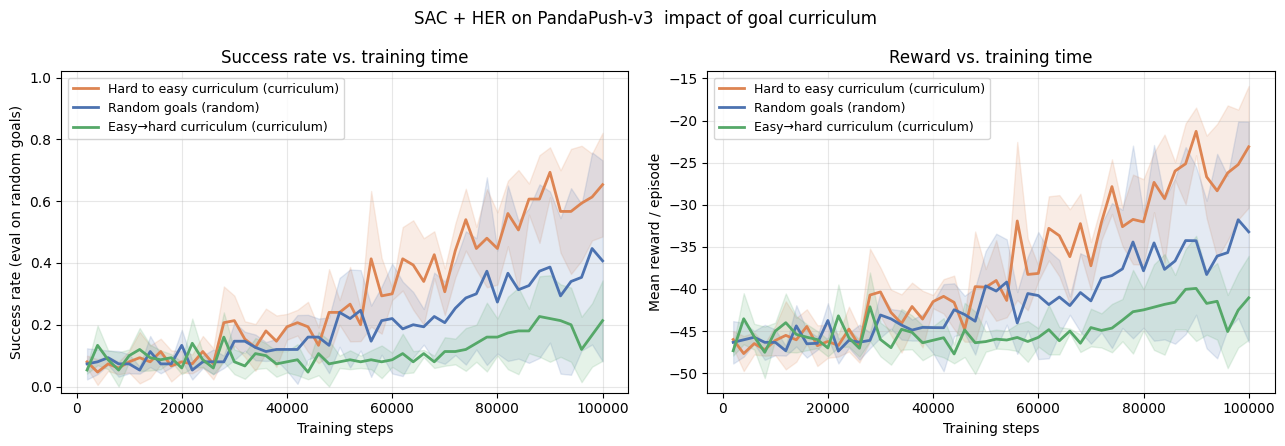

In [8]:
COLORS = {
    "hardtoeasy": "#DD8452",       # orange
    "random": "#4C72B0",      # blue
    "easytohard": "#55A868",  # green
}
LABELS = {
    "hardtoeasy": "Hard to easy curriculum (curriculum)",
    "random": "Random goals (random)",
    "easytohard": "Easy→hard curriculum (curriculum)",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for strategy in STRATEGIES:
    sub = df[df["strategy"] == strategy]
    agg = sub.groupby("timesteps").agg(
        success_mean=("success_rate", "mean"),
        success_std=("success_rate", "std"),
        reward_mean=("mean_reward", "mean"),
        reward_std=("mean_reward", "std"),
    ).reset_index()

    color = COLORS[strategy]
    label = LABELS[strategy]

    axes[0].plot(agg["timesteps"], agg["success_mean"], label=label, color=color, linewidth=2)
    if agg["success_std"].notna().any() and len(SEEDS) > 1:
        axes[0].fill_between(
            agg["timesteps"],
            (agg["success_mean"] - agg["success_std"]).clip(lower=0),
            (agg["success_mean"] + agg["success_std"]).clip(upper=1),
            color=color, alpha=0.15,
        )

    axes[1].plot(agg["timesteps"], agg["reward_mean"], label=label, color=color, linewidth=2)
    if agg["reward_std"].notna().any() and len(SEEDS) > 1:
        axes[1].fill_between(
            agg["timesteps"],
            agg["reward_mean"] - agg["reward_std"],
            agg["reward_mean"] + agg["reward_std"],
            color=color, alpha=0.15,
        )

axes[0].set_xlabel("Training steps")
axes[0].set_ylabel("Success rate (eval on random goals)")
axes[0].set_ylim(-0.02, 1.02)
axes[0].set_title("Success rate vs. training time")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=9)

axes[1].set_xlabel("Training steps")
axes[1].set_ylabel("Mean reward / episode")
axes[1].set_title("Reward vs. training time")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=9)

fig.suptitle(f"SAC + HER on {ENV_ID}  impact of goal curriculum", fontsize=12)
fig.tight_layout()
plt.show()